<a href="https://colab.research.google.com/github/inosven/Neural-Networks-Zero-to-Hero/blob/main/makemore_MLP_excercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
try:
  from google.colab import drive
  drive.mount('/content/drive')
  data_path = '/content/drive/MyDrive/Colab Notebooks/Zero2Hero_Karpathy/Data/names.txt'
except ImportError:  # running locally
  data_path = 'Data/names.txt'
with open(data_path,'r') as f:
  text = f.read().splitlines()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
words = text
words[:5]

['emma', 'olivia', 'ava', 'isabella', 'sophia']

In [ ]:
import torch
import torch.nn.functional as F
from matplotlib import pyplot as plt
%matplotlib inline

In [ ]:
chars = sorted(list(set(''.join(words))))

In [ ]:
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [ ]:
block_size = 4

In [ ]:
def build_dataset(words):
  X, Y = [], []
  for w in words:
      context = [0] * block_size
      for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix]
  X=torch.tensor(X)
  Y=torch.tensor(Y)
  return X,Y

In [ ]:
import random
random.seed(42)
random.shuffle(words)
n1 = int(len(words)*0.8)
n2 = int(len(words)*0.9)

Xtr,Ytr = build_dataset(words[:n1])
Xval, Yval = build_dataset(words[n1:n2])
Xtes, Ytes = build_dataset(words[n2:])


In [ ]:
Xtr.shape

torch.Size([182625, 4])

In [ ]:
g = torch.Generator().manual_seed(45678)
C = torch.randn((27,10), generator=g)
W1= torch.randn((40,200),generator=g)
b1 = torch.randn(200,generator=g)
W2 = torch.randn((200,27),generator=g)
b2 = torch.randn(27,generator=g)
parameters = [C, W1, b1, W2, b2]

In [ ]:
sum(p.nelement() for p in parameters)

13897

In [ ]:
lre = torch.linspace(-3,0,1000)
lrs = 10**lre

In [ ]:
for p in parameters:
  p.requires_grad=True

In [ ]:
lri = []
lossi = []
stepi = []


In [ ]:
for i in range(1000):
  # batch
  ix = torch.randint(0,Xval.shape[0], (50,))
  # foward pass
  emb = C[Xval[ix]]
  h = torch.tanh(emb.view(-1,40) @ W1 + b1)
  logits  = h @ W2 + b2
  loss = F.cross_entropy(logits, Yval[ix])
  # backward
  for p in parameters:
    p.grad = None
  loss.backward()
  # update

  lr = lrs[i]
  for p in parameters:
    p.data += -lr*p.grad

  # track
  lri.append(lre[i])
  lossi.append(loss.item())

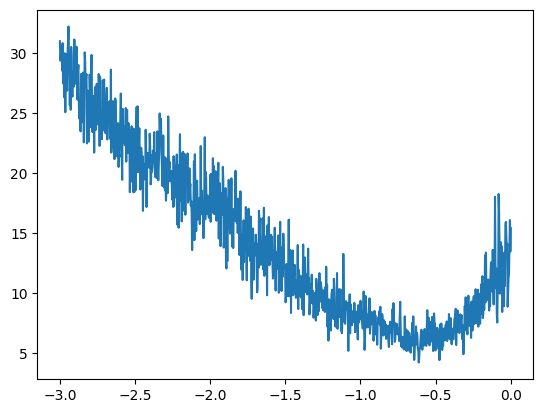

In [ ]:
plt.plot(lri,lossi)

In [ ]:
# Therefore, pick -0.75

In [ ]:
g = torch.Generator().manual_seed(6874)
C = torch.randn((27,10),generator=g)
W1 = torch.randn((40,200),generator=g)
b1 = torch.randn(200,generator=g)
W2 = torch.randn((200,27),generator=g)
b2 = torch.randn(27,generator=g)


In [ ]:
parameters = [C,W1,b1,W2,b2]

In [ ]:
for p in parameters:
  p.requires_grad=True

In [ ]:
lossi = []
stepi = []


In [ ]:
for i in range(50000):
  # batch
  ix = torch.randint(0,Xtr.shape[0],(50,))
  # forward pass
  emb = C[Xtr[ix]]
  h = torch.tanh(emb.view(-1,40) @ W1 + b1)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Ytr[ix])

  #backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # udpate
  if i < 20000:
    lr = 10**(-0.75)
  elif 20000<=i<40000:
    lr = 10**(-1.75)
  else:
    lr = 10**(-2.75)
  for p in parameters:
    p.data += -lr*p.grad
  # track
  lossi.append(loss.item())
  stepi.append(i)

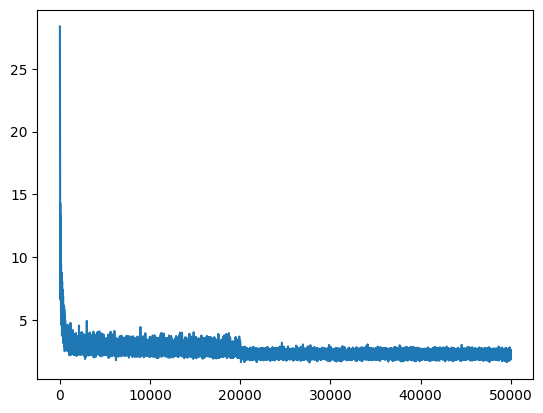

In [ ]:
plt.plot(stepi,lossi)

In [ ]:
emb = C[Xval]
h = torch.tanh(emb.view(-1,40) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Yval)
loss

tensor(2.2442, grad_fn=<NllLossBackward0>)

In [ ]:
emb = C[Xtr]
h = torch.tanh(emb.view(-1,40) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.2277, grad_fn=<NllLossBackward0>)

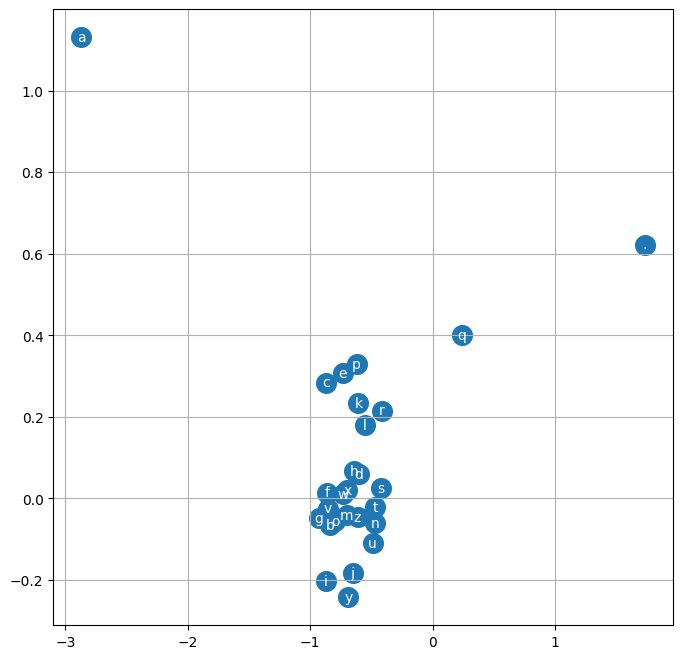

In [ ]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color="white")
plt.grid('minor')

In [ ]:
# predict
g = torch.Generator().manual_seed(42)
for _ in range(20):
  out = []
  context = [0] * block_size
  while True:
     emb = C[torch.tensor([context])]
     h = torch.tanh(emb.view(1,-1) @ W1 + b1)
     logits = h @ W2 + b2
     prob= F.softmax(logits,dim=1)
     ix = torch.multinomial(prob,num_samples=1,replacement=True,generator=g).item()
     context = context[1:]+[ix]
     out.append(ix)
     if ix==0:
      break
  print(''.join(itos[i] for i in out))

anueren.
tis.
mabi.
nedyn.
shan.
silaylen.
keman.
lavin.
emiah.
nasi.
dizi.
kerch.
jordon.
kalla.
mimolynn.
acveria.
acha.
kaitian.
tuhelisa.
jach.


In [ ]:
g = torch.Generator().manual_seed(6874)
C = torch.randn((27,10),generator=g)
W1 = torch.randn((40,200),generator=g)
b1 = torch.randn(200,generator=g)
W2 = torch.randn((200,300),generator=g)
b2 = torch.randn(300,generator=g)
W3 = torch.randn((300,27),generator=g)
b3 = torch.randn(27,generator=g)


In [ ]:
parameters = [C,W1,b1,W2,b2, W3, b3]

In [ ]:
for p in parameters:
  p.requires_grad=True

In [ ]:
lossi = []
lri = []


In [ ]:
for i in range(1000):
  # batch
  ix = torch.randint(0,Xval.shape[0], (50,))
  # foward pass
  emb = C[Xval[ix]]
  h = torch.tanh(emb.view(-1,40) @ W1 + b1)
  h2  = h @ W2 + b2
  logits = h2 @ W3 + b3
  loss = F.cross_entropy(logits, Yval[ix])
  # backward
  for p in parameters:
    p.grad = None
  loss.backward()
  # update

  lr = lrs[i]
  for p in parameters:
    p.data += -lr*p.grad

  # track
  lri.append(lre[i])
  lossi.append(loss.item())

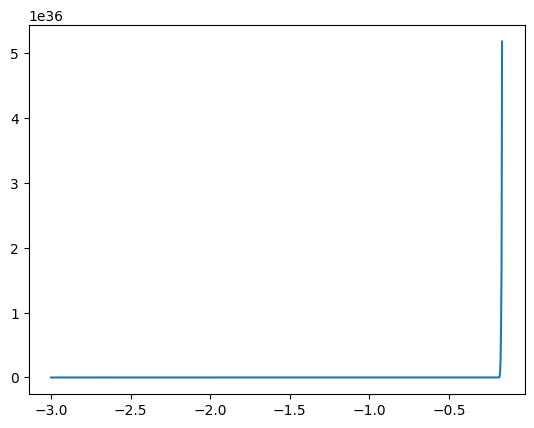

In [ ]:
plt.plot(lri,lossi)

In [ ]:
loss

tensor(nan, grad_fn=<NllLossBackward0>)

### 修复 NaN 问题：引入合理的权重初始化缩放 (Kaiming / Xavier 思想)

In [ ]:
import torch
import torch.nn.functional as F

g = torch.Generator().manual_seed(6874)

# 适当减小初始权重的缩放比例，防止前向传播时数值发生爆炸
C = torch.randn((27, 10), generator=g) * 0.1

# 对于 tanh 激活层，推荐使用 Kaiming 初始缩放系数 (5/3) / sqrt(fan_in)
W1 = torch.randn((40, 200), generator=g) * ((5/3) / (40**0.5))
b1 = torch.randn(200, generator=g) * 0.01

W2 = torch.randn((200, 300), generator=g) * ((5/3) / (200**0.5))
b2 = torch.randn(300, generator=g) * 0.01

# 输出层一般不加激活函数，可以使用较小的初始值以便在开始时输出较均匀的概率分布
W3 = torch.randn((300, 27), generator=g) * (1.0 / (300**0.5))
b3 = torch.randn(27, generator=g) * 0

parameters = [C, W1, b1, W2, b2, W3, b3]

for p in parameters:
    p.requires_grad = True

print(f"总参数量: {sum(p.nelement() for p in parameters)}")

总参数量: 76897


现在让我们重新运行这 1000 步的学习率探寻。因为我们控制了权重的初始化，这次 Loss 将不会再变成 `NaN`。

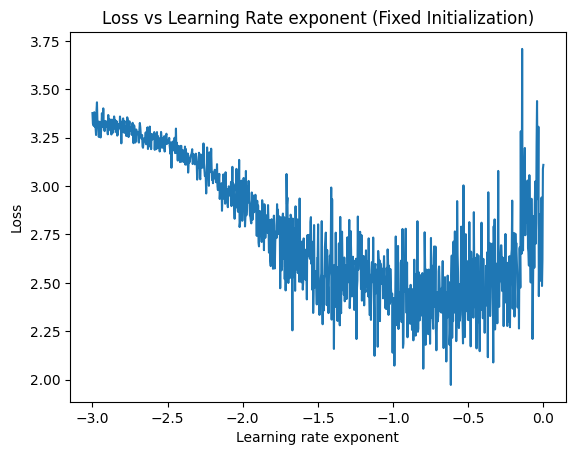

In [ ]:
lossi = []
lri = []

for i in range(1000):
  # minibatch
  ix = torch.randint(0, Xval.shape[0], (50,))

  # forward pass
  emb = C[Xval[ix]]
  h = torch.tanh(emb.view(-1, 40) @ W1 + b1)
  h2 = torch.tanh(h @ W2 + b2) # 建议加上激活函数激活，否则两层线性相当于一层
  logits = h2 @ W3 + b3
  loss = F.cross_entropy(logits, Yval[ix])

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update using range of learning rates
  lr = lrs[i]
  for p in parameters:
    p.data += -lr * p.grad

  # track
  lri.append(lre[i])
  lossi.append(loss.item())

import matplotlib.pyplot as plt
plt.plot(lri, lossi)
plt.title("Loss vs Learning Rate exponent (Fixed Initialization)")
plt.xlabel("Learning rate exponent")
plt.ylabel("Loss")
plt.show()

In [ ]:
batch_sizes = [32,64,128]

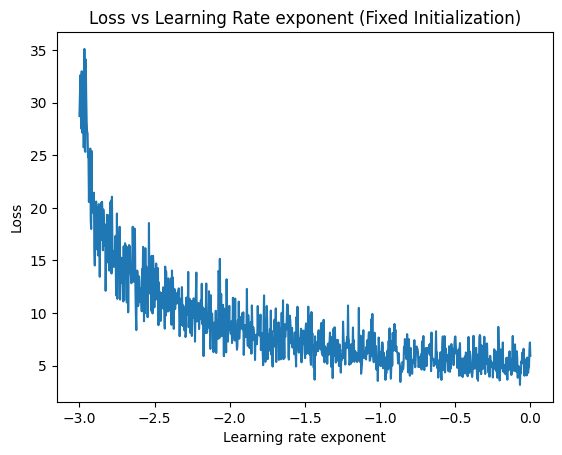

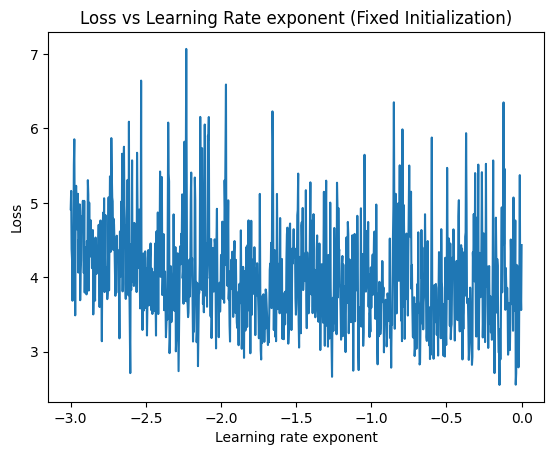

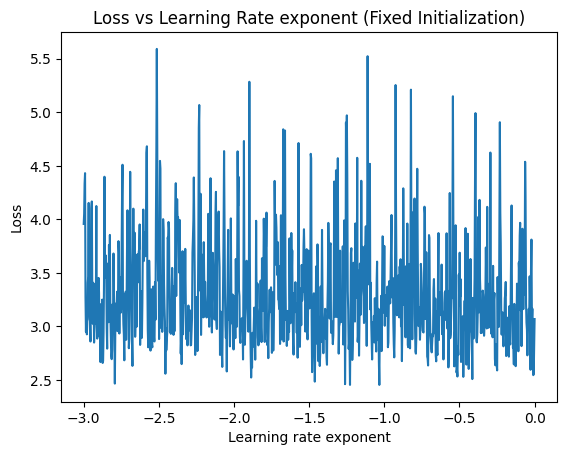

In [ ]:
for batch_size in batch_sizes:
  lossi = []
  lri = []

  for i in range(1000):
    # minibatch

    ix = torch.randint(0, Xval.shape[0], (batch_size,))

    # forward pass
    emb = C[Xval[ix]]
    h = torch.tanh(emb.view(-1, 40) @ W1 + b1)
    h2 = torch.tanh(h @ W2 + b2) # 建议加上激活函数激活，否则两层线性相当于一层
    logits = h2 @ W3 + b3
    loss = F.cross_entropy(logits, Yval[ix])

    # backward pass
    for p in parameters:
      p.grad = None
    loss.backward()

    # update using range of learning rates
    lr = 10**(-1)
    for p in parameters:
      p.data += -lr * p.grad

    # track
    lri.append(lre[i])
    lossi.append(loss.item())

  import matplotlib.pyplot as plt
  plt.plot(lri, lossi)
  plt.title("Loss vs Learning Rate exponent (Fixed Initialization)")
  plt.xlabel("Learning rate exponent")
  plt.ylabel("Loss")
  plt.show()

### 实验：在同一张图表上对比不同 Batch Size 的训练 Loss 与收敛轨迹

正在训练 Batch Size = 32 ...
正在训练 Batch Size = 64 ...
正在训练 Batch Size = 128 ...


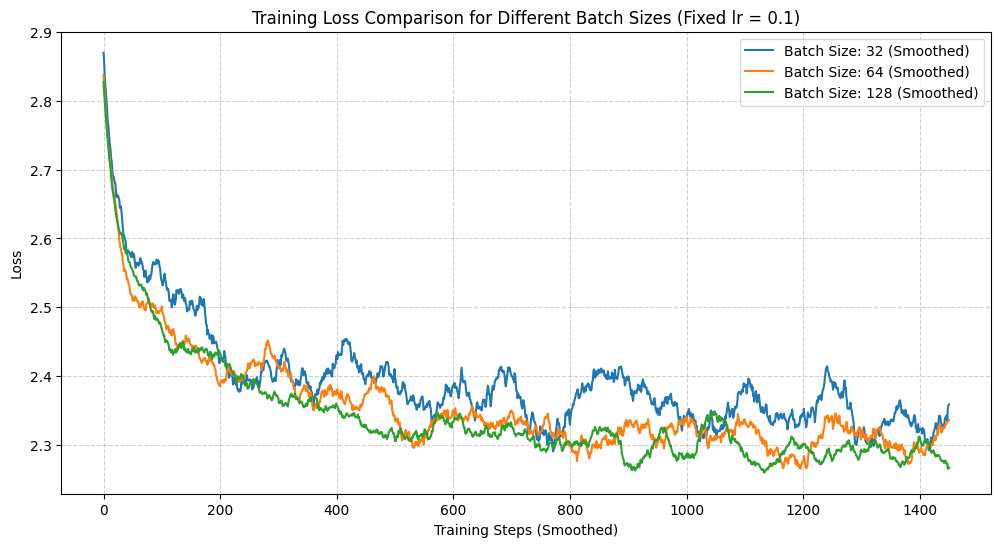

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# 定义我们要对比的 batch sizes
batch_sizes = [32, 64, 128]
results = {} # 用于存储每个 batch size 的 loss 历史

# 设定相同的迭代步数进行公平对比
num_steps = 1500

for bs in batch_sizes:
    print(f"正在训练 Batch Size = {bs} ...")

    # 1. 每次实验必须使用相同的随机种子重新初始化参数，确保对比的公平性
    g = torch.Generator().manual_seed(61874)
    C_exp = torch.randn((27, 10), generator=g) * 0.1
    W1_exp = torch.randn((40, 200), generator=g) * ((5/3) / (40**0.5))
    b1_exp = torch.randn(200, generator=g) * 0.01
    W2_exp = torch.randn((200, 300), generator=g) * ((5/3) / (200**0.5))
    b2_exp = torch.randn(300, generator=g) * 0.01
    W3_exp = torch.randn((300, 27), generator=g) * (1.0 / (300**0.5))
    b3_exp = torch.randn(27, generator=g) * 0

    params = [C_exp, W1_exp, b1_exp, W2_exp, b2_exp, W3_exp, b3_exp]
    for p in params:
        p.requires_grad = True

    loss_history = []

    # 2. 开始训练循环
    for i in range(num_steps):
        # 构建 minibatch
        ix = torch.randint(0, Xtr.shape[0], (bs,))

        # 前向传播
        emb = C_exp[Xtr[ix]]
        h = torch.tanh(emb.view(-1, 40) @ W1_exp + b1_exp)
        h2 = torch.tanh(h @ W2_exp + b2_exp)
        logits = h2 @ W3_exp + b3_exp
        loss = F.cross_entropy(logits, Ytr[ix])

        # 反向传播
        for p in params:
            p.grad = None
        loss.backward()

        # 选用一个在 Kaiming 初始化下合理的、统一的学习率进行基准测试 (例如 0.1)
        lr = 0.1
        for p in params:
            p.data += -lr * p.grad

        loss_history.append(loss.item())

    results[bs] = loss_history

# 3. 绘制对比图表
plt.figure(figsize=(12, 6))
for bs, losses in results.items():
    # 为了看得更清，我们对原始 Loss 使用滑动窗口平滑一下（也可以不平滑直接画）
    # 这里画出平滑后的曲线
    losses_tensor = torch.tensor(losses)
    smoothed_losses = losses_tensor.unfold(0, 50, 1).mean(1) # 50步平滑
    plt.plot(smoothed_losses.numpy(), label=f'Batch Size: {bs} (Smoothed)')

plt.title('Training Loss Comparison for Different Batch Sizes (Fixed lr = 0.1)')
plt.xlabel('Training Steps (Smoothed)')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
g = torch.Generator().manual_seed(61874)
C = torch.randn((27,10),generator=g)
W1 = torch.randn((40,200),generator=g)
b1 = torch.randn(200,generator=g)
W2 = torch.randn((200,300),generator=g)
b2 = torch.randn(300,generator=g)
W3 = torch.randn((300,27),generator=g)
b3 = torch.randn(27,generator=g)


In [ ]:
lossi = []
stepi = []

In [ ]:
parameters = [C,W1,b1,W2,b2, W3, b3]

In [ ]:
sum(p.nelement() for p in parameters)

76897

In [ ]:
for p in parameters:
  p.requires_grad=True

In [166]:
# pick -1.0
for i in range(50000):
  # batch
  ix = torch.randint(0,Xtr.shape[0], (128,))
  # foward pass
  emb = C[Xtr[ix]]
  h = torch.tanh(emb.view(-1,40) @ W1 + b1)
  h2  = torch.tanh(h @ W2 + b2)
  logits = h2 @ W3 + b3
  loss = F.cross_entropy(logits, Ytr[ix])
  # backward
  for p in parameters:
    p.grad = None
  loss.backward()
  # udpate
  if i < 20000:
    lr = 10**(-1)
  elif 20000<=i<40000:
    lr = 10**(-2)
  else:
    lr = 10**(-3)
  for p in parameters:
    p.data += -lr*p.grad
  # track
  lossi.append(loss.item())
  stepi.append(i)

In [167]:
loss

tensor(2.3847, grad_fn=<NllLossBackward0>)

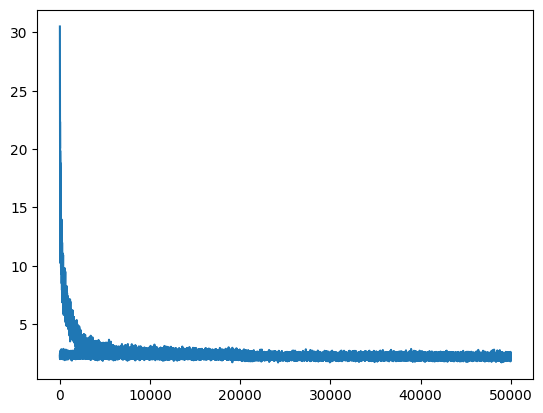

In [171]:
plt.plot(stepi,lossi)

In [172]:
emb = C[Xval]
h = torch.tanh(emb.view(-1,40) @ W1 + b1)
h2  = torch.tanh(h @ W2 + b2)
logits = h2 @ W3 + b3
loss= F.cross_entropy(logits,Yval)
loss

tensor(2.2798, grad_fn=<NllLossBackward0>)

In [173]:
g = torch.Generator().manual_seed(456)

In [174]:
for _ in range(20):
  context = [0] * 4
  out = []
  while True:
    emb = C[torch.tensor([context])]
    h1 = torch.tanh(emb.view(1,-1)@W1+b1)
    h2 = torch.tanh(h1@W2+b2)
    logits = h2@W3+b3
    prob = F.softmax(logits,dim=1)
    ix = torch.multinomial(prob,num_samples=1,replacement=True,generator=g).item()
    context = context[1:] + [ix]
    out.append(ix)
    if ix==0:
      break
  print(''.join(itos[i] for i in out))

sali.
myedtecia.
pimla.
kamvi.
tylie.
devaanyan.
kocralahil.
kema.
oliirca.
deabon.
elyhaypik.
bayi.
coftonal.
ayholdy.
kaisanand.
lanayrum.
aneon.
rewtt.
juraybel.
zensly.
